In [4]:
display("text/html", "<style>.container { width:100% !important; }</style>")

- Make a 2 by 7 figure of the rank-frequency curves

In [5]:
using DataFrames, CSV, Plots, LaTeXStrings, DelimitedFiles, GLM

In [6]:
Plots.theme(:dao)

In [7]:
include("./diversity-simulator.jl")
using .dsim

In [8]:
pal = cgrad(:tol_muted);
cpal10 = [pal[i] for i in 0.0:1/46:1]

In [9]:
length(cpal10)

47

In [10]:
read_data = CSV.read("./Data_csv/Grilli-crosssecdata__datatax.csv", DataFrame)
read_data = filter(:nreads => !=(0), read_data)
# first split on classification
gd1 = groupby(read_data, :classification);

In [11]:
gd1;

For each classification, split up on the sample.

In [12]:
gd_classes = []
for gd in gd1
    push!(gd_classes, groupby(gd, :sample_id))
end

In [13]:
length.(gd_classes)

14-element Vector{Int64}:
 476
  93
 316
  22
 112
 508
   3
 123
  30
  25
 188
 198
  57
 575

In [14]:
gd_classes[7];

In [15]:
argmin([gd_classes[6][i][!,:count] for i in 1:length(gd_classes[6])])

354

Get the names of the different classes.

In [16]:
classes = [gd_classes[i][1][!,:classification][2] for i in 1:length(gd_classes)]
classes = strip.(lowercase.(classes))
classes[10] = "marine hydrothermal vents"
classes[6] = "oral cavity"
classes[5] = "terrestrial soil"
classes[end] = "activated sludge"
classes

14-element Vector{SubString{String}}:
 "seawater"
 "oral"
 "gut"
 "vaginal"
 "terrestrial soil"
 "oral cavity"
 "feces"
 "skin"
 "glacier"
 "marine hydrothermal vents"
 "river"
 "lake"
 "environmental aquatic marine"
 "activated sludge"

# Class 1: Seawater

Now let's make the rank-frequency plots.

In [17]:
si = sortperm(length.([x[!,:count] for x in gd_classes[1]]), rev = true);

In [18]:
cpal = [pal[i] for i in 0.0:1/10:1];

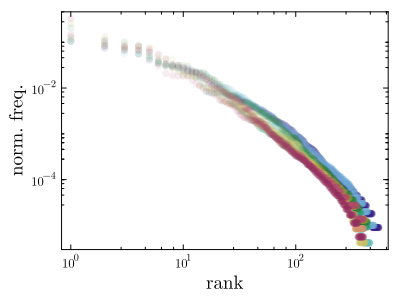

In [19]:
scatter(sort(gd_classes[1][si[1]][!,:count]./sum(gd_classes[1][si[1]][!,:count]), rev = true), xaxis = :log, yaxis = :log, color = cpal[1], alpha = 0.1)
for i in 2:10
    scatter!(sort(gd_classes[1][si[i]][!,:count]./sum(gd_classes[1][si[i]][!,:count]), rev = true), color = cpal[i], alpha = 0.1)
end
scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none)

In [27]:
cpal20 = [pal[i] for i in 0.0:1/20:1];

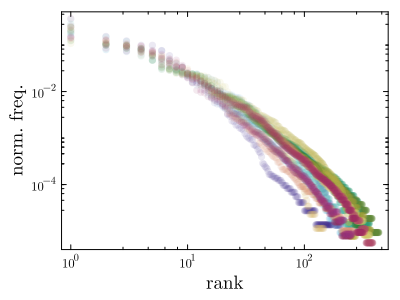

In [29]:
scatter(sort(gd_classes[1][1][!,:count]./sum(gd_classes[1][1][!,:count]), rev = true), xaxis = :log, yaxis = :log, color = cpal20[1], alpha = 0.1)
for i in 2:20
    scatter!(sort(gd_classes[1][i][!,:count]./sum(gd_classes[1][i][!,:count]), rev = true), color = cpal20[i], alpha = 0.1)
end
scatter!(legend = :none, ylabel = "norm. freq.", xlabel = "rank", size = (400,300), grid = :none, minorgrid = :none)

Need to automate this procedure for all categories.

## Automating the plots.

In [22]:
length(gd_classes[1])

476

In [34]:
rf_plots = [];
for j in 1:length(gd_classes)
    if j == 7 # feces contains only three data points
        continue
    end
    rf_plot = scatter(sort(gd_classes[j][1][!,:count]./sum(gd_classes[j][1][!,:count]), rev = true), xaxis = :log, yaxis = :log, color = cpal20[1], alpha = 0.1, title = classes[j])
    for i in 2:minimum([20, length(gd_classes[j])])
        scatter!(sort(gd_classes[j][i][!,:count]./sum(gd_classes[j][i][!,:count]), rev = true), color = cpal20[i], alpha = 0.1)
    end
    scatter!(legend = :none, size = (400,300), grid = :none, minorgrid = :none)
    if j == 6
        plot!(ylabel = "normalized freqeuncy", ylabelfontsize = 15)
    elseif j == 14
        plot!(xlabel = "rank", xlabelfontsize = 15)
    end
    push!(rf_plots, rf_plot)
end    

In [35]:
using Plots.Measures

In [36]:
plot(rf_plots..., layout = (3,5), size = (1500,800), left_margin = 10mm, bottom_margin = 7mm)
savefig("Grilli-RF-Plot.pdf")

"/home/jamesh/GitHub/Ecological-Preferential-Attachment/Grilli-RF-Plot.pdf"